# Projeto Final Aplicado – Ciência de Dados no Setor Público
## Análise Econométrica e Estatística da Celeridade Processual nos Tribunais de Justiça Estaduais (2015–2025)
**Disciplina:** Fundamentos em Ciência de Dados  
**Tema:** A Razoável Duração do Processo (Art. 5º, LXXVIII da CF/88) e os Determinantes da Baixa Processual no 1º Grau  
**Base de Dados:** Indicadores do CNJ (Justiça em Números), IBGE e IPEA (`base_davi_lemes_ferreira_reduzida.csv`)  
---


## 1. Definição do Problema Público e Justificativa

### 1.1 O Conflito Constitucional e a Morosidade Judicial
A Emenda Constitucional nº 45/2004 assegurou, no **artigo 5º, inciso LXXVIII da Constituição Federal**, o direito fundamental à **razoável duração do processo** e aos meios que garantam a celeridade de sua tramitação. No entanto, a gestão do Poder Judiciário brasileiro enfrenta profundas assimetrias regionais e gargalos estruturais. A lentidão na baixa processual afeta negativamente o ambiente de negócios, a segurança jurídica e a confiança dos cidadãos nas instituições.

### 1.2 Objetivo da Pesquisa
Este estudo analisa os determinantes do indicador **`tpbaixcncrim1m`** — *tempo médio, em dias, decorrido até a baixa dos processos de conhecimento não criminais no 1º grau de jurisdição* — cobrindo os 27 Tribunais de Justiça estaduais no período de 2015 a 2025.

Buscamos responder às seguintes questões centrais:
1. **Recursos x Celeridade:** Aumentar a força de trabalho e os orçamentos reduz diretamente o tempo de tramitação?
2. **Carga de Trabalho e Estoque:** Qual o impacto relativo do acervo pendente por magistrado e da carga por servidor na celeridade?
3. **Gargalos Estruturais:** Quais variáveis apresentam maior poder explicativo para a variação da morosidade entre os estados?


## 2. Coleta, Tratamento e Preparação dos Dados em Python

Nesta etapa, carregamos a base de dados em formato CSV (`base_davi_lemes_ferreira_reduzida.csv`) e seu respectivo dicionário (`dicionario_davi_lemes_ferreira.csv`), contendo 292 observações para os 27 TJs ao longo dos anos de 2015 a 2025.

### Tratamento de Dados:
- Identificação e conversão dos separadores decimais (vírgula `,` para ponto `.`).
- Tipagem adequada das variáveis numéricas contínuas e inteiras.
- Verificação de valores ausentes e registros duplicados.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Configuração de exibição do pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Carregando a base de dados e o dicionário
df_raw = pd.read_csv('/workspace/knowledge/base_davi_lemes_ferreira_reduzida.csv', sep=';')
dic = pd.read_csv('/workspace/knowledge/dicionario_davi_lemes_ferreira.csv', sep=';')

# Cópia para tratamento
df = df_raw.copy()

# Conversão das colunas numéricas de vírgula para ponto
num_cols = [c for c in df.columns if c not in ['sigla', 'ano']]
for col in num_cols:
    if df[col].dtype == object:
        df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

print("=== ESTRUTURA E TIPOS DE DADOS APÓS TRATAMENTO ===")
print(df.info())

print("\n=== VERIFICAÇÃO DE VALORES AUSENTES ===")
print(df.isnull().sum())


=== ESTRUTURA E TIPOS DE DADOS APÓS TRATAMENTO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 292 entries, 0 to 291
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   sigla                   292 non-null    object 
 1   ano                     292 non-null    int64  
 2   tpbaixcncrim1m          292 non-null    float64
 3   estoque_por_magistrado  292 non-null    float64
 4   litigiosidade           292 non-null    float64
 5   despesa_rel             292 non-null    float64
 6   carga_por_servidor      292 non-null    float64
 7   afastamento_por_mag     292 non-null    float64
 8   densidade_demografica   292 non-null    float64
 9   log_h1                  292 non-null    float64
 10  f3                      292 non-null    float64
dtypes: float64(9), int64(1), object(1)
memory usage: 25.2+ KB
None

=== VERIFICAÇÃO DE VALORES AUSENTES ===
sigla                     0
ano               

## 3. Análise Estatística Exploratória e Medidas Descritivas

A Tabela a seguir apresenta as principais medidas de tendência central e dispersão (média, mediana, desvio padrão, mínimo, máximo e quartis) para todas as variáveis analíticas do estudo.


In [2]:
desc_stats = df[num_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc_stats.columns = ['Média', 'Desv. Padrão', 'Mínimo', '1º Quartil', 'Mediana', '3º Quartil', 'Máximo']
print("=== MEDIDAS DE POSIÇÃO E DISPERSÃO DA BASE DE DADOS ===")
print(desc_stats.round(2))


=== MEDIDAS DE POSIÇÃO E DISPERSÃO DA BASE DE DADOS ===
                         Média  Desv. Padrão   Mínimo  1º Quartil  Mediana  3º Quartil    Máximo
tpbaixcncrim1m          886.18        376.74   200.64      608.23   859.92     1091.50   2438.00
estoque_por_magistrado 4348.48       2925.57  1042.35     2690.25  3494.38     4834.73  19911.82
litigiosidade          5943.42       2235.79  2041.72     4230.36  5781.50     7376.56  14242.46
despesa_rel               1.00          0.52     0.28        0.68     0.84        1.13      2.80
carga_por_servidor      276.06        148.39    65.78      176.21   238.98      356.77    809.53
afastamento_por_mag      28.49         18.69     0.00       15.13    26.34       38.80    157.54
densidade_demografica    75.56        117.57     2.25        6.82    35.84       86.21    535.35
log_h1                   15.36          1.02    13.13       14.85    15.21       16.05     17.66
f3                      160.51         66.06    64.75      107.64   152

### 3.1 Análise da Distribuição da Variável-Alvo (`tpbaixcncrim1m`)

O tempo médio de baixa varia amplamente entre os TJs estaduais, oscilando entre **200,6 dias** (pico de eficiência) e **2.438,0 dias** (mais de 6,6 anos de duração média). A média geral é de **886,2 dias** (~2,4 anos), com mediana de **859,9 dias**, indicando uma leve assimetria à direita.


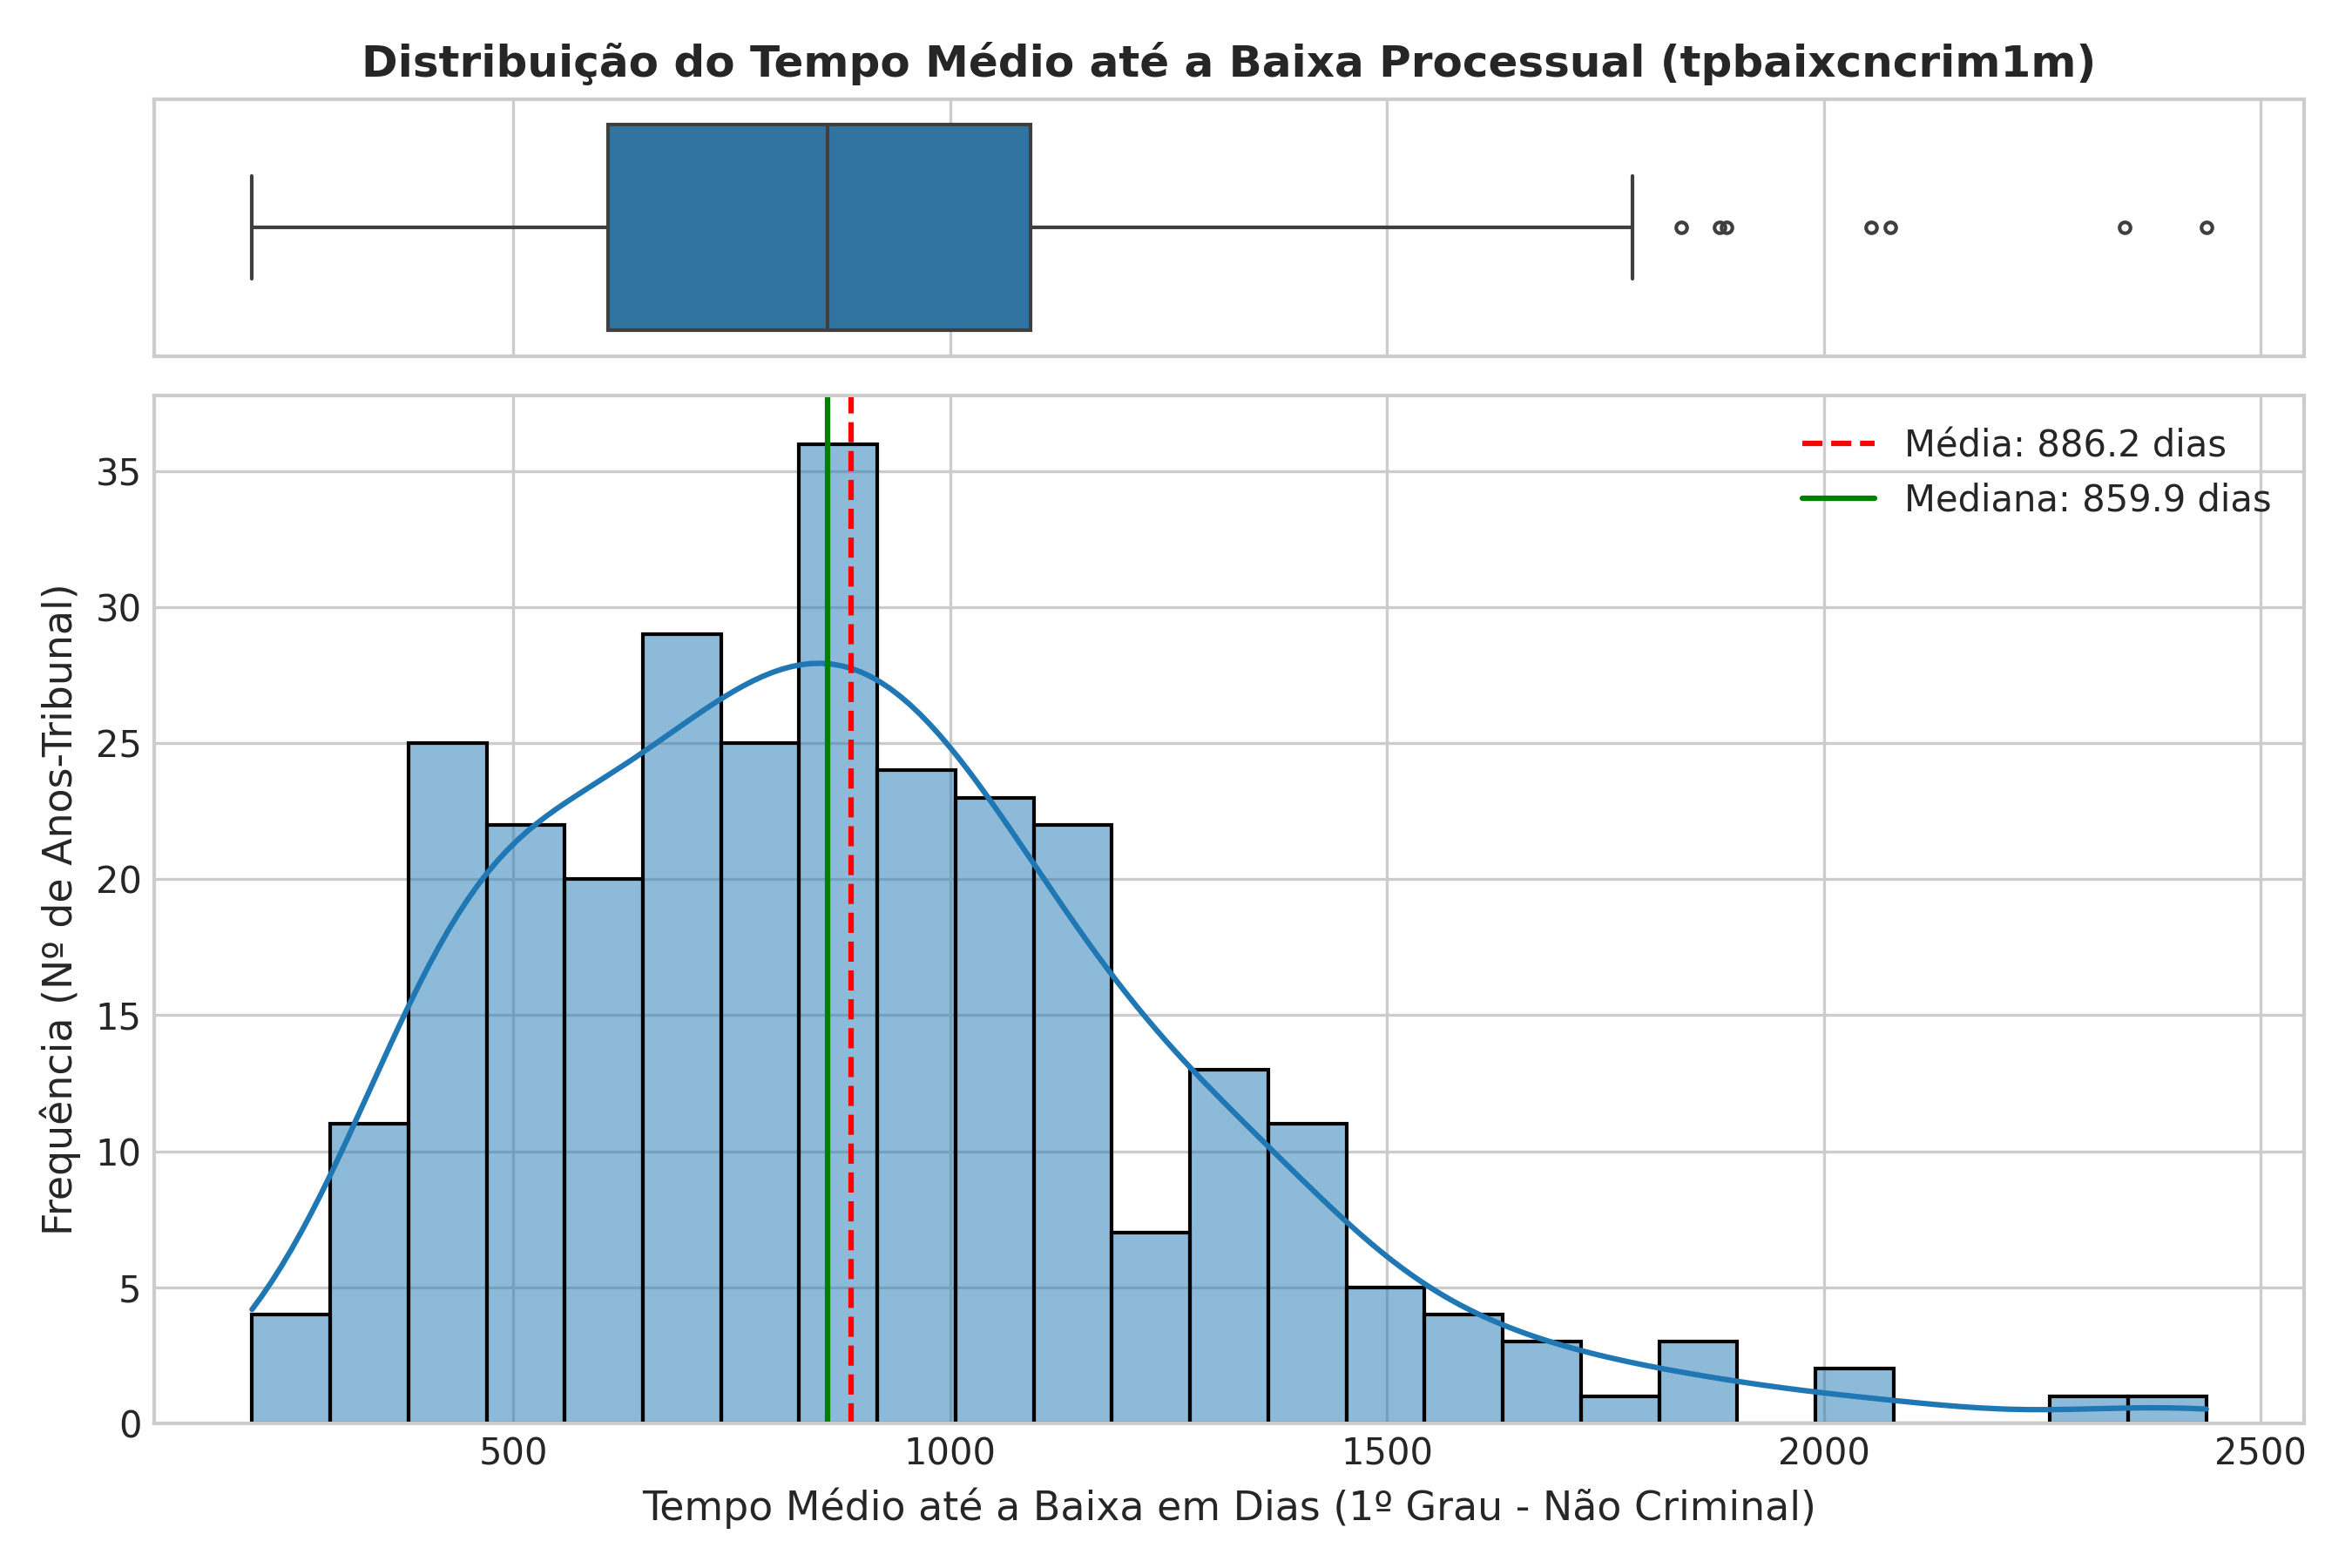

In [3]:
# Código de visualização da distribuição do target
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, gridspec_kw={'height_ratios': [0.2, 0.8]})
sns.boxplot(x=df['tpbaixcncrim1m'], ax=ax_box, color='#1f77b4')
sns.histplot(df['tpbaixcncrim1m'], kde=True, ax=ax_hist, color='#1f77b4', bins=25)
plt.tight_layout()
plt.show()

### 3.2 Matriz de Correlação e Limites Analíticos

A análise de correlação linear de Pearson revela os seguintes padrões fundamentais com a variável-alvo (`tpbaixcncrim1m`):
- **Força de trabalho por 100k hab. (`f3`):** Correlação negativa forte ($r = -0,55$). TJs com maior força de trabalho relativa apresentam menor tempo de baixa.
- **Despesa relativa por processo (`despesa_rel`):** Correlação negativa forte ($r = -0,53$). Maior aporte financeiro relativo associa-se a maior celeridade.
- **Tamanho da População (`log_h1`):** Correlação positiva expressiva ($r = +0,53$). Estados mais populosos enfrentam maior morosidade média.
- **Estoque por Magistrado (`estoque_por_magistrado`):** Correlação positiva forte ($r = +0,51$). Acervos acumulados são o principal gargalo operacional.
- **Carga por Servidor (`carga_por_servidor`):** Correlação positiva forte ($r = +0,52$). Sobrecarga de servidores atrasa a tramitação.
- **Litigiosidade (`litigiosidade`):** Correlação negativa ($r = -0,42$). Tribunais com maior litigiosidade per capita costumam ser estruturados com processos de trabalho mais ágeis.

> **Aviso Metodológico — Correlação vs. Causalidade:** A correlação mede apenas associação linear. Uma alta correlação não implica necessariamente relação causal direta, podendo ser intermediada por variáveis omitidas ou sofrer de causalidade reversa.

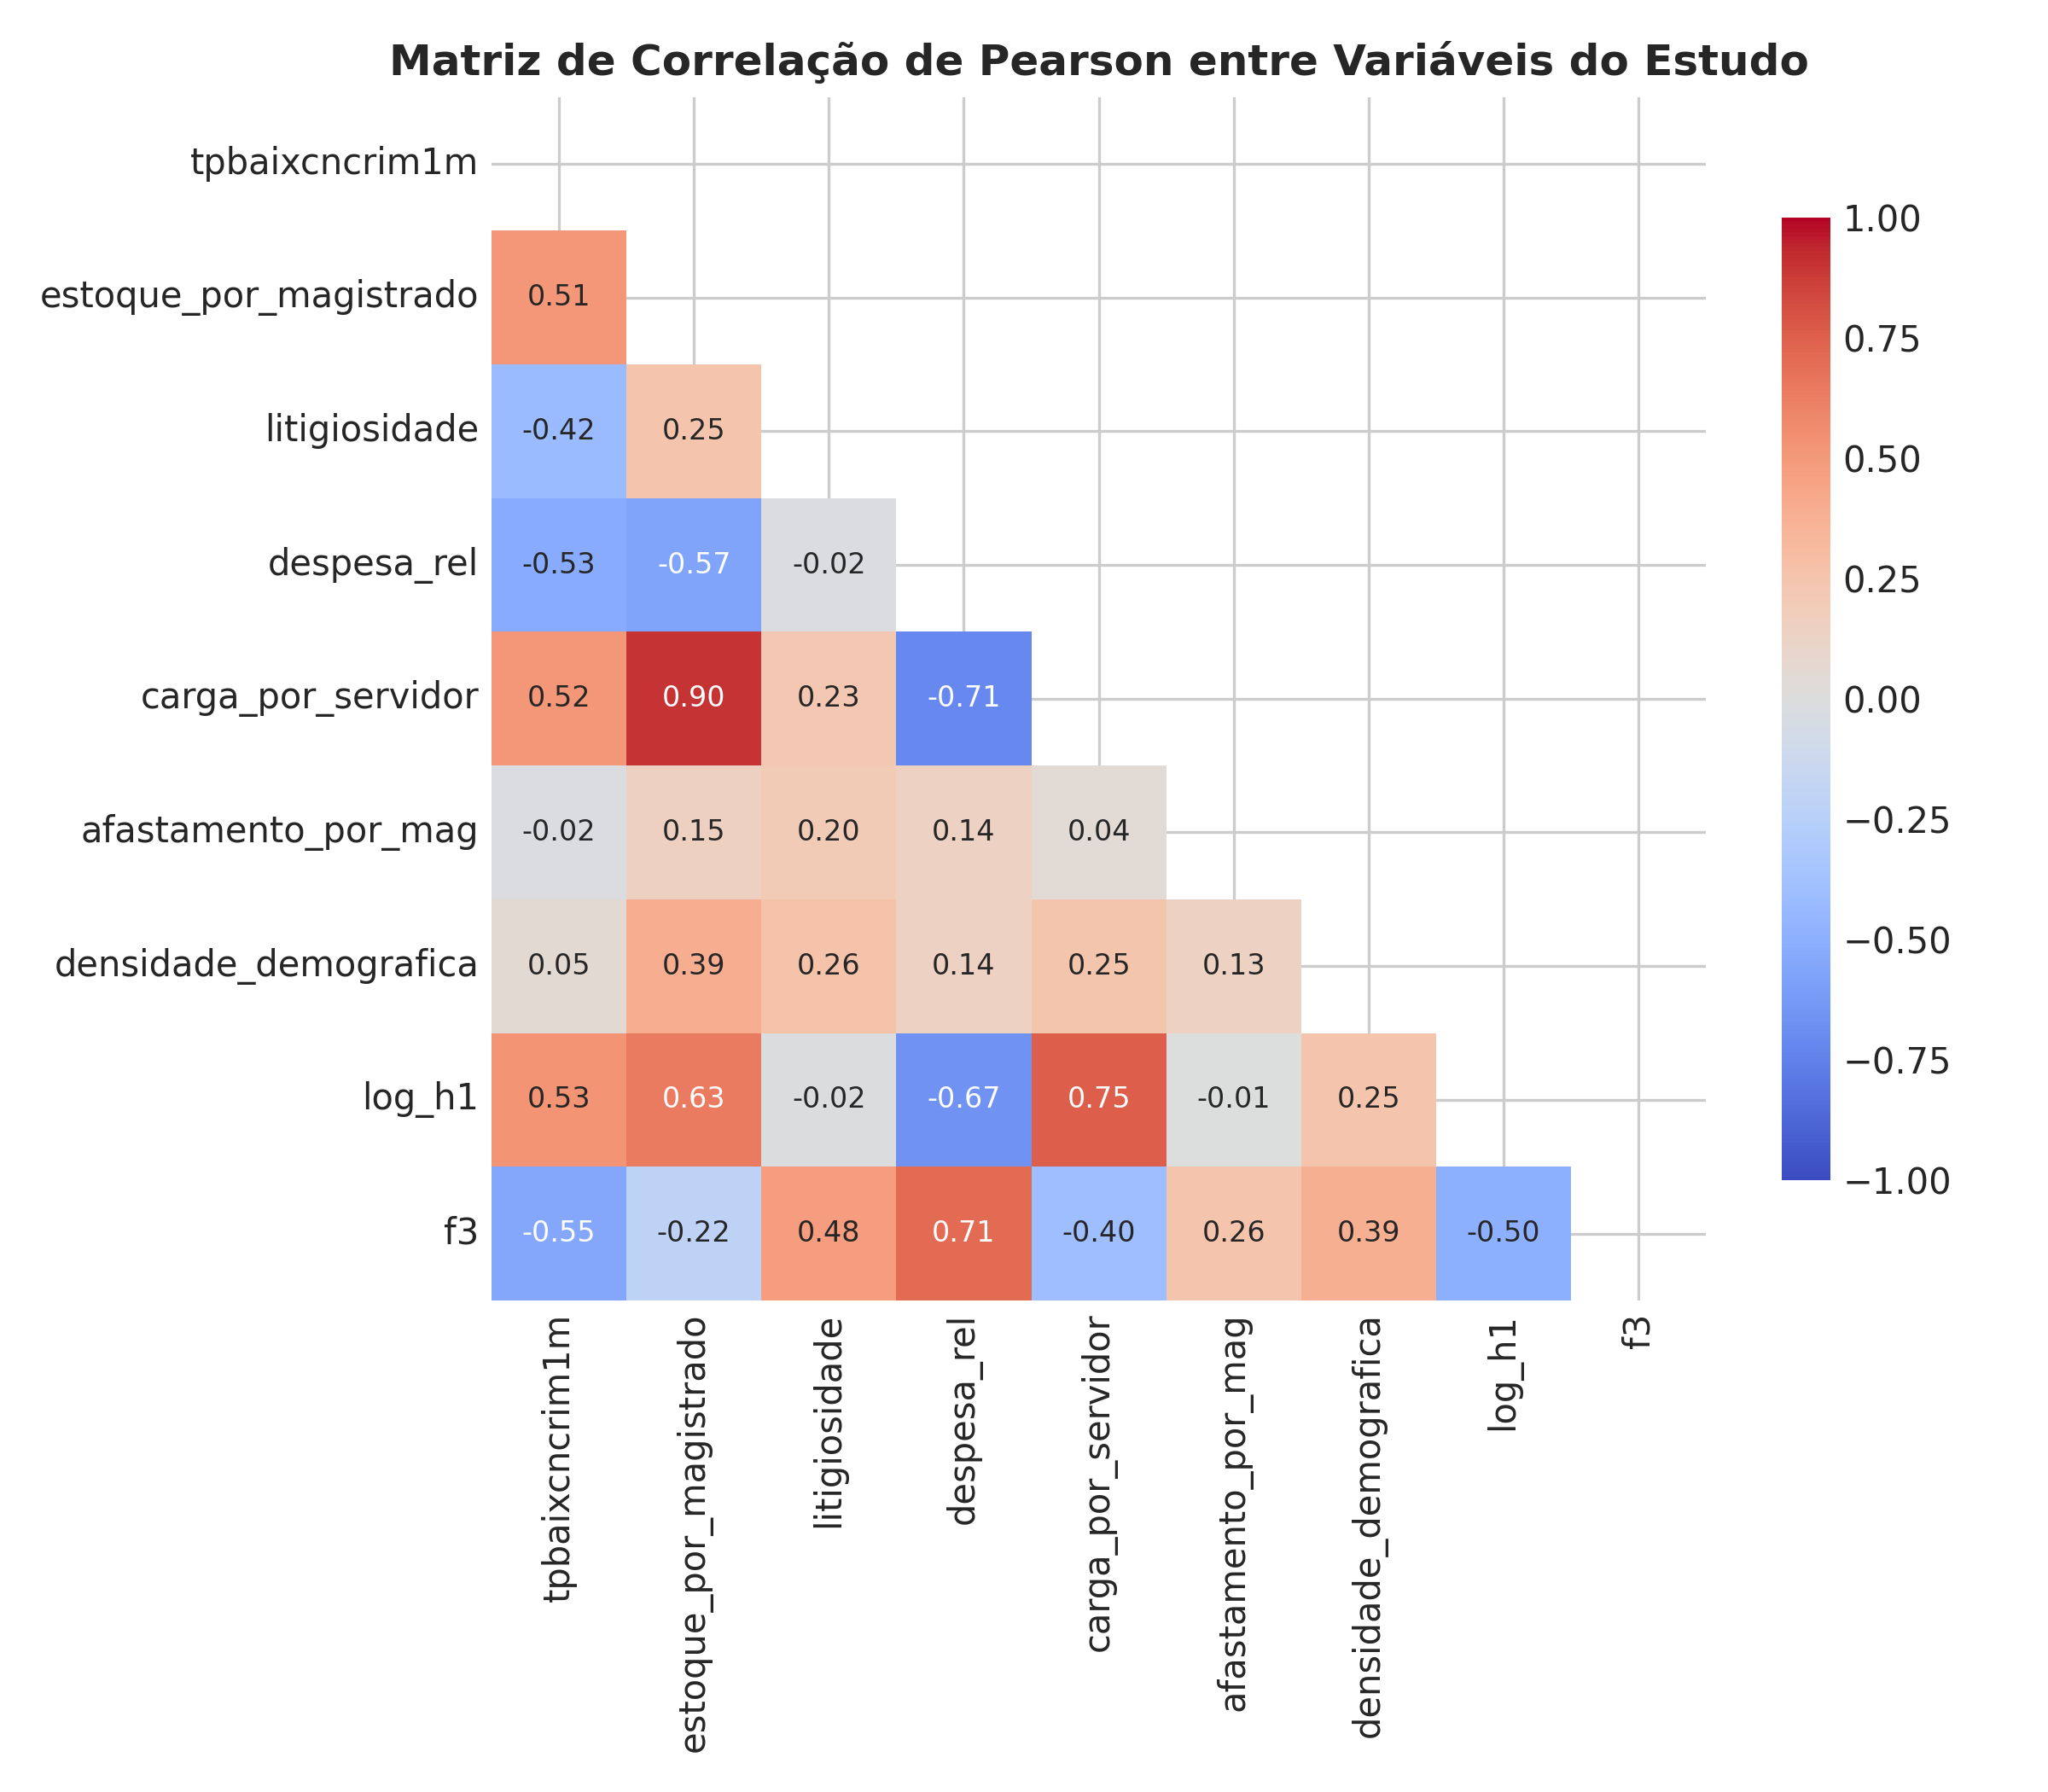

In [4]:
# Matriz de Correlação de Pearson
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlação de Pearson')
plt.show()

## 3.3 Modelagem Econométrica — Regressão Linear Múltipla (OLS)

Para isolar o efeito específico de cada determinante sobre o tempo de baixa, estimamos modelos econométricos por MQO (Mínimos Quadrados Ordinários):
- **Modelo 1:** Bivariado (`tpbaixcncrim1m ~ f3`)
- **Modelo 2:** Múltiplo completo (`tpbaixcncrim1m ~ f3 + estoque_por_magistrado + carga_por_servidor + log_h1 + despesa_rel + litigiosidade`)


In [5]:
# Estimação dos modelos econométricos
m1 = smf.ols('tpbaixcncrim1m ~ f3', data=df).fit()
m2 = smf.ols('tpbaixcncrim1m ~ f3 + estoque_por_magistrado + carga_por_servidor + log_h1 + despesa_rel + litigiosidade', data=df).fit()

print("=== SUMÁRIO DO MODELO 2 (REGRESSÃO MÚLTIPLA OLS) ===")
print(m2.summary())


=== SUMÁRIO DO MODELO 2 (REGRESSÃO MÚLTIPLA OLS) ===
                            OLS Regression Results                            
Dep. Variable:         tpbaixcncrim1m   R-squared:                       0.631
Model:                            OLS   Adj. R-squared:                  0.623
Method:                 Least Squares   F-statistic:                     81.09
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           9.67e-59
No. Observations:                 292   AIC:                             4015.
Df Residuals:                     285   BIC:                             4041.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                948.2752    334.345      2.83

### 3.4 Diagnóstico de Resíduos do Modelo Múltiplo

O Modelo 2 explica **63,1% da variância total** ($R^2 = 0,631$) do tempo médio de baixa. A análise de resíduos confirma homocedasticidade razoável e distribuição próxima da normalidade na região central.

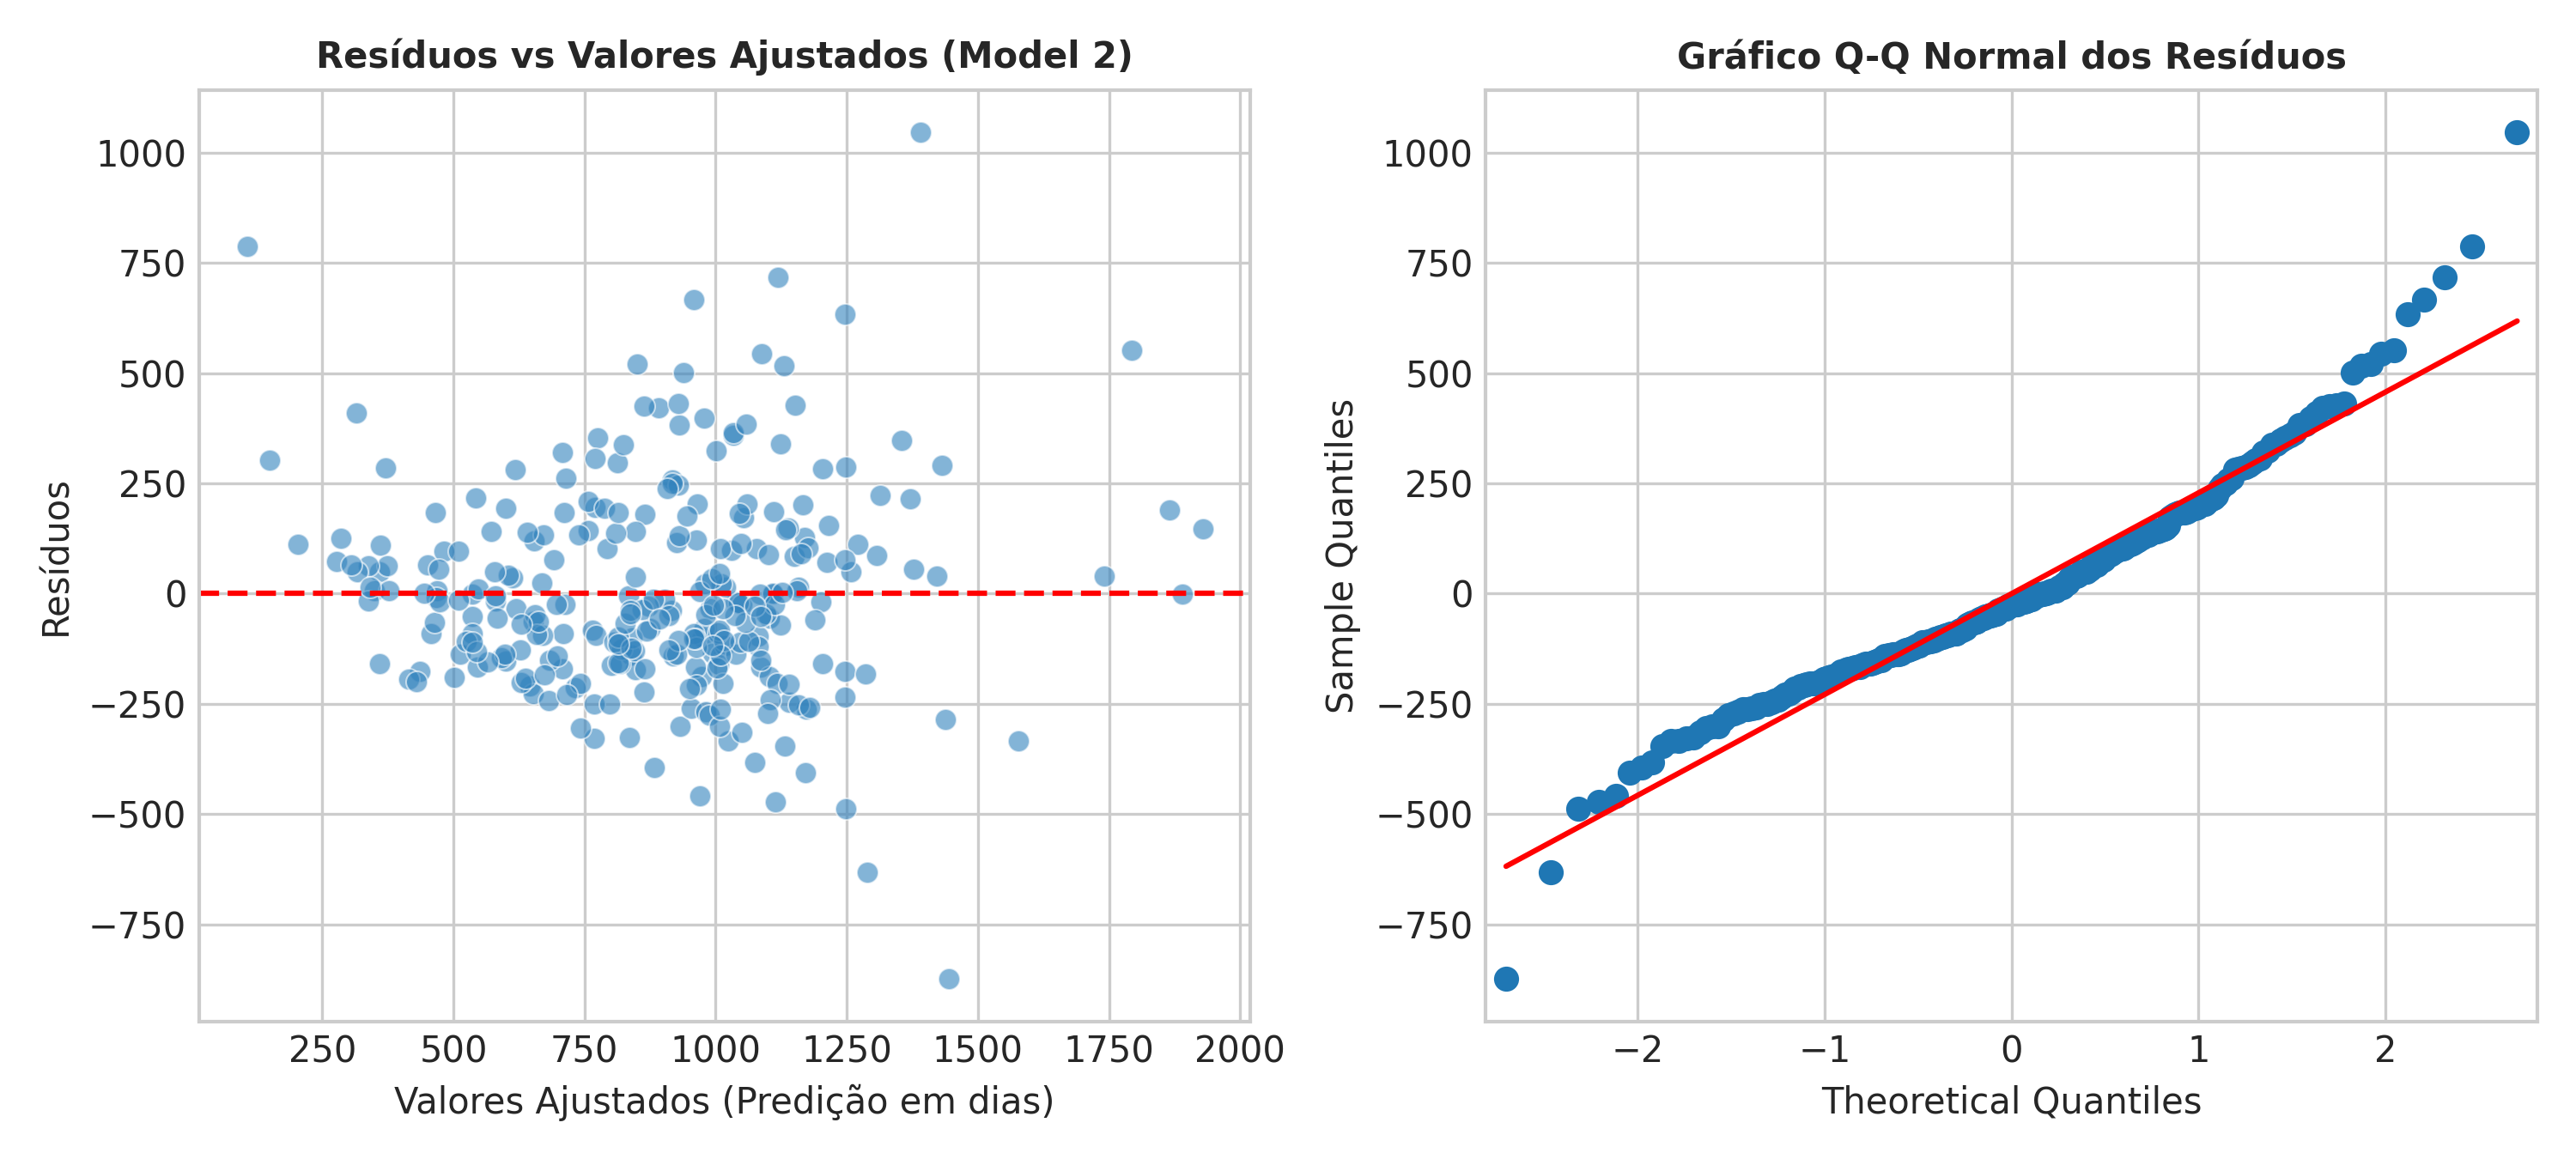

In [6]:
# Diagnóstico de resíduos
residuals = m2.resid
fitted = m2.fittedvalues
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))
sns.scatterplot(x=fitted, y=residuals, ax=ax1, alpha=0.6)
ax1.axhline(0, color='red', linestyle='--')
sm.qqplot(residuals, line='s', ax=ax2)
plt.tight_layout()
plt.show()

## 4. Storytelling e Comunicação de Resultados para a Gestão Pública

A narrativa analítica estrutura-se em três partes:
1. **O Cenário Inicial:** Disparidade abissal entre tribunais estaduais.
2. **O Gargalo Central:** O acervo pendente acumulado por magistrado (`estoque_por_magistrado`) como gargalo crítico.
3. **A Alocação Eficiente:** O peso da eficiência orçamentária (`despesa_rel`) em detrimento do simples aumento quantitativo de pessoal.

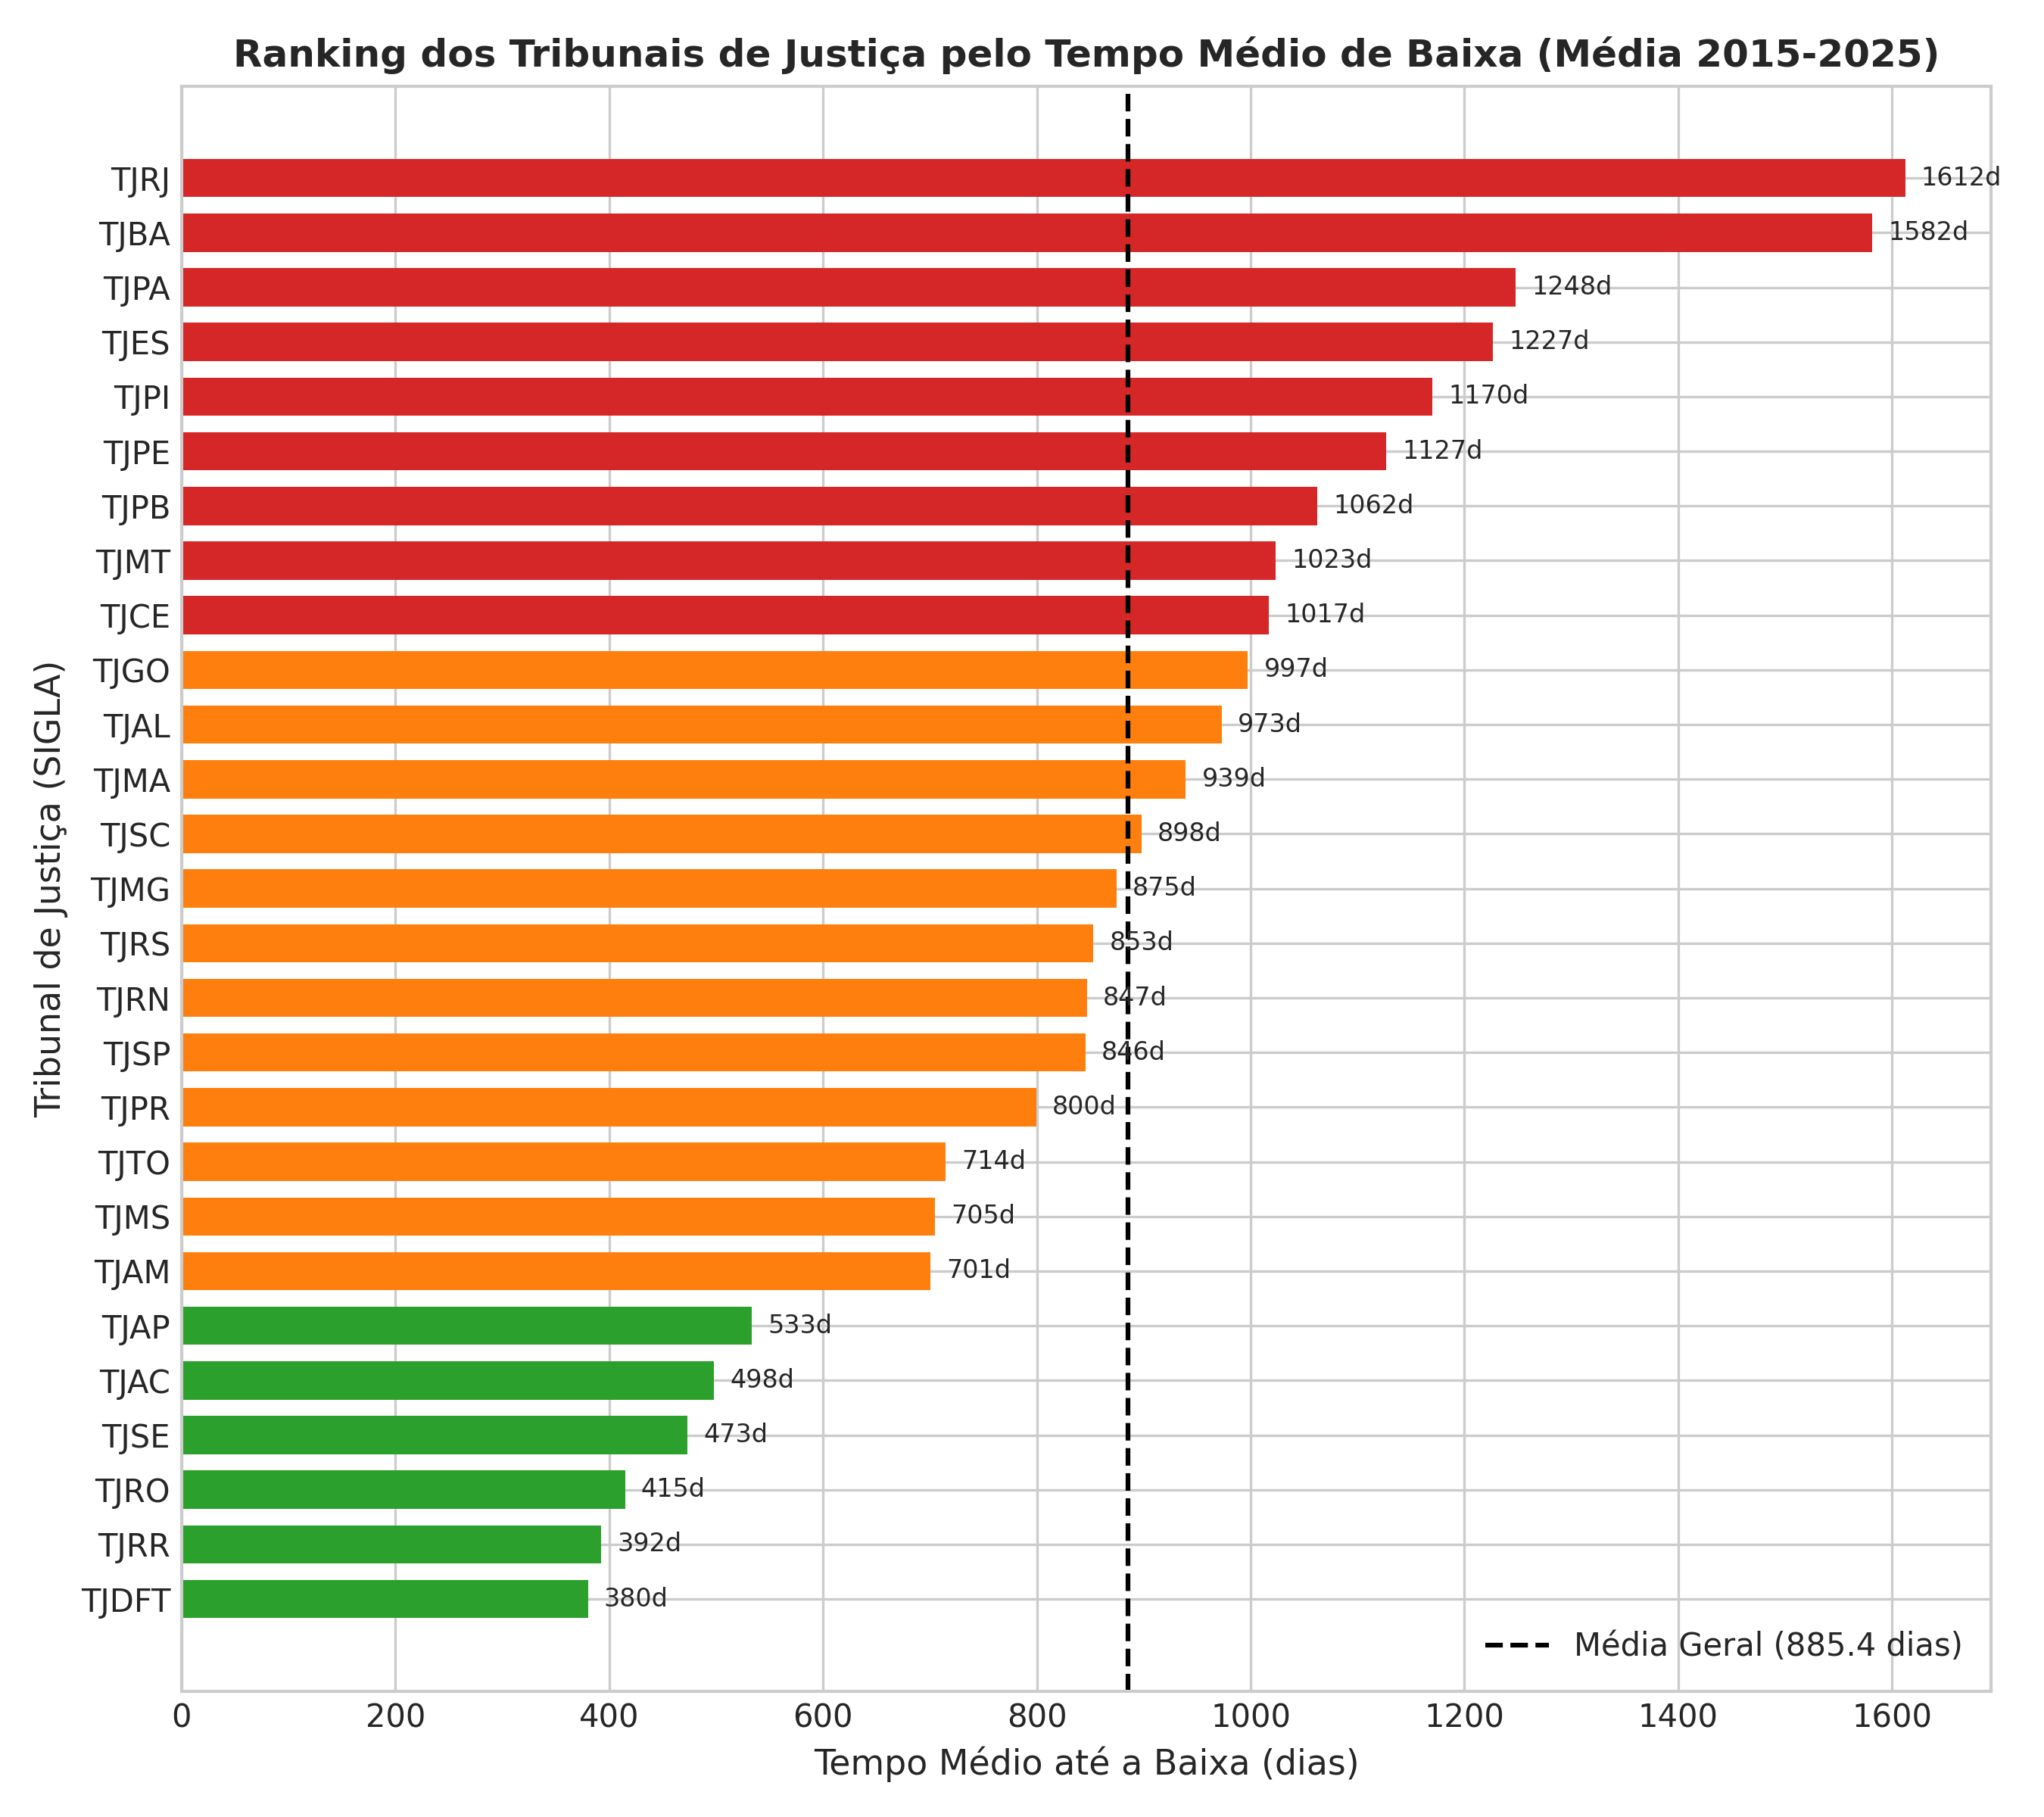

In [7]:
# Ranking dos Tribunais pelo tempo médio de baixa
ranking = df.groupby('sigla')['tpbaixcncrim1m'].mean().sort_values()
plt.figure(figsize=(9, 7))
plt.barh(ranking.index, ranking.values, color='#1f77b4')
plt.title('Ranking dos TJs pelo Tempo Médio de Baixa (dias)')
plt.show()

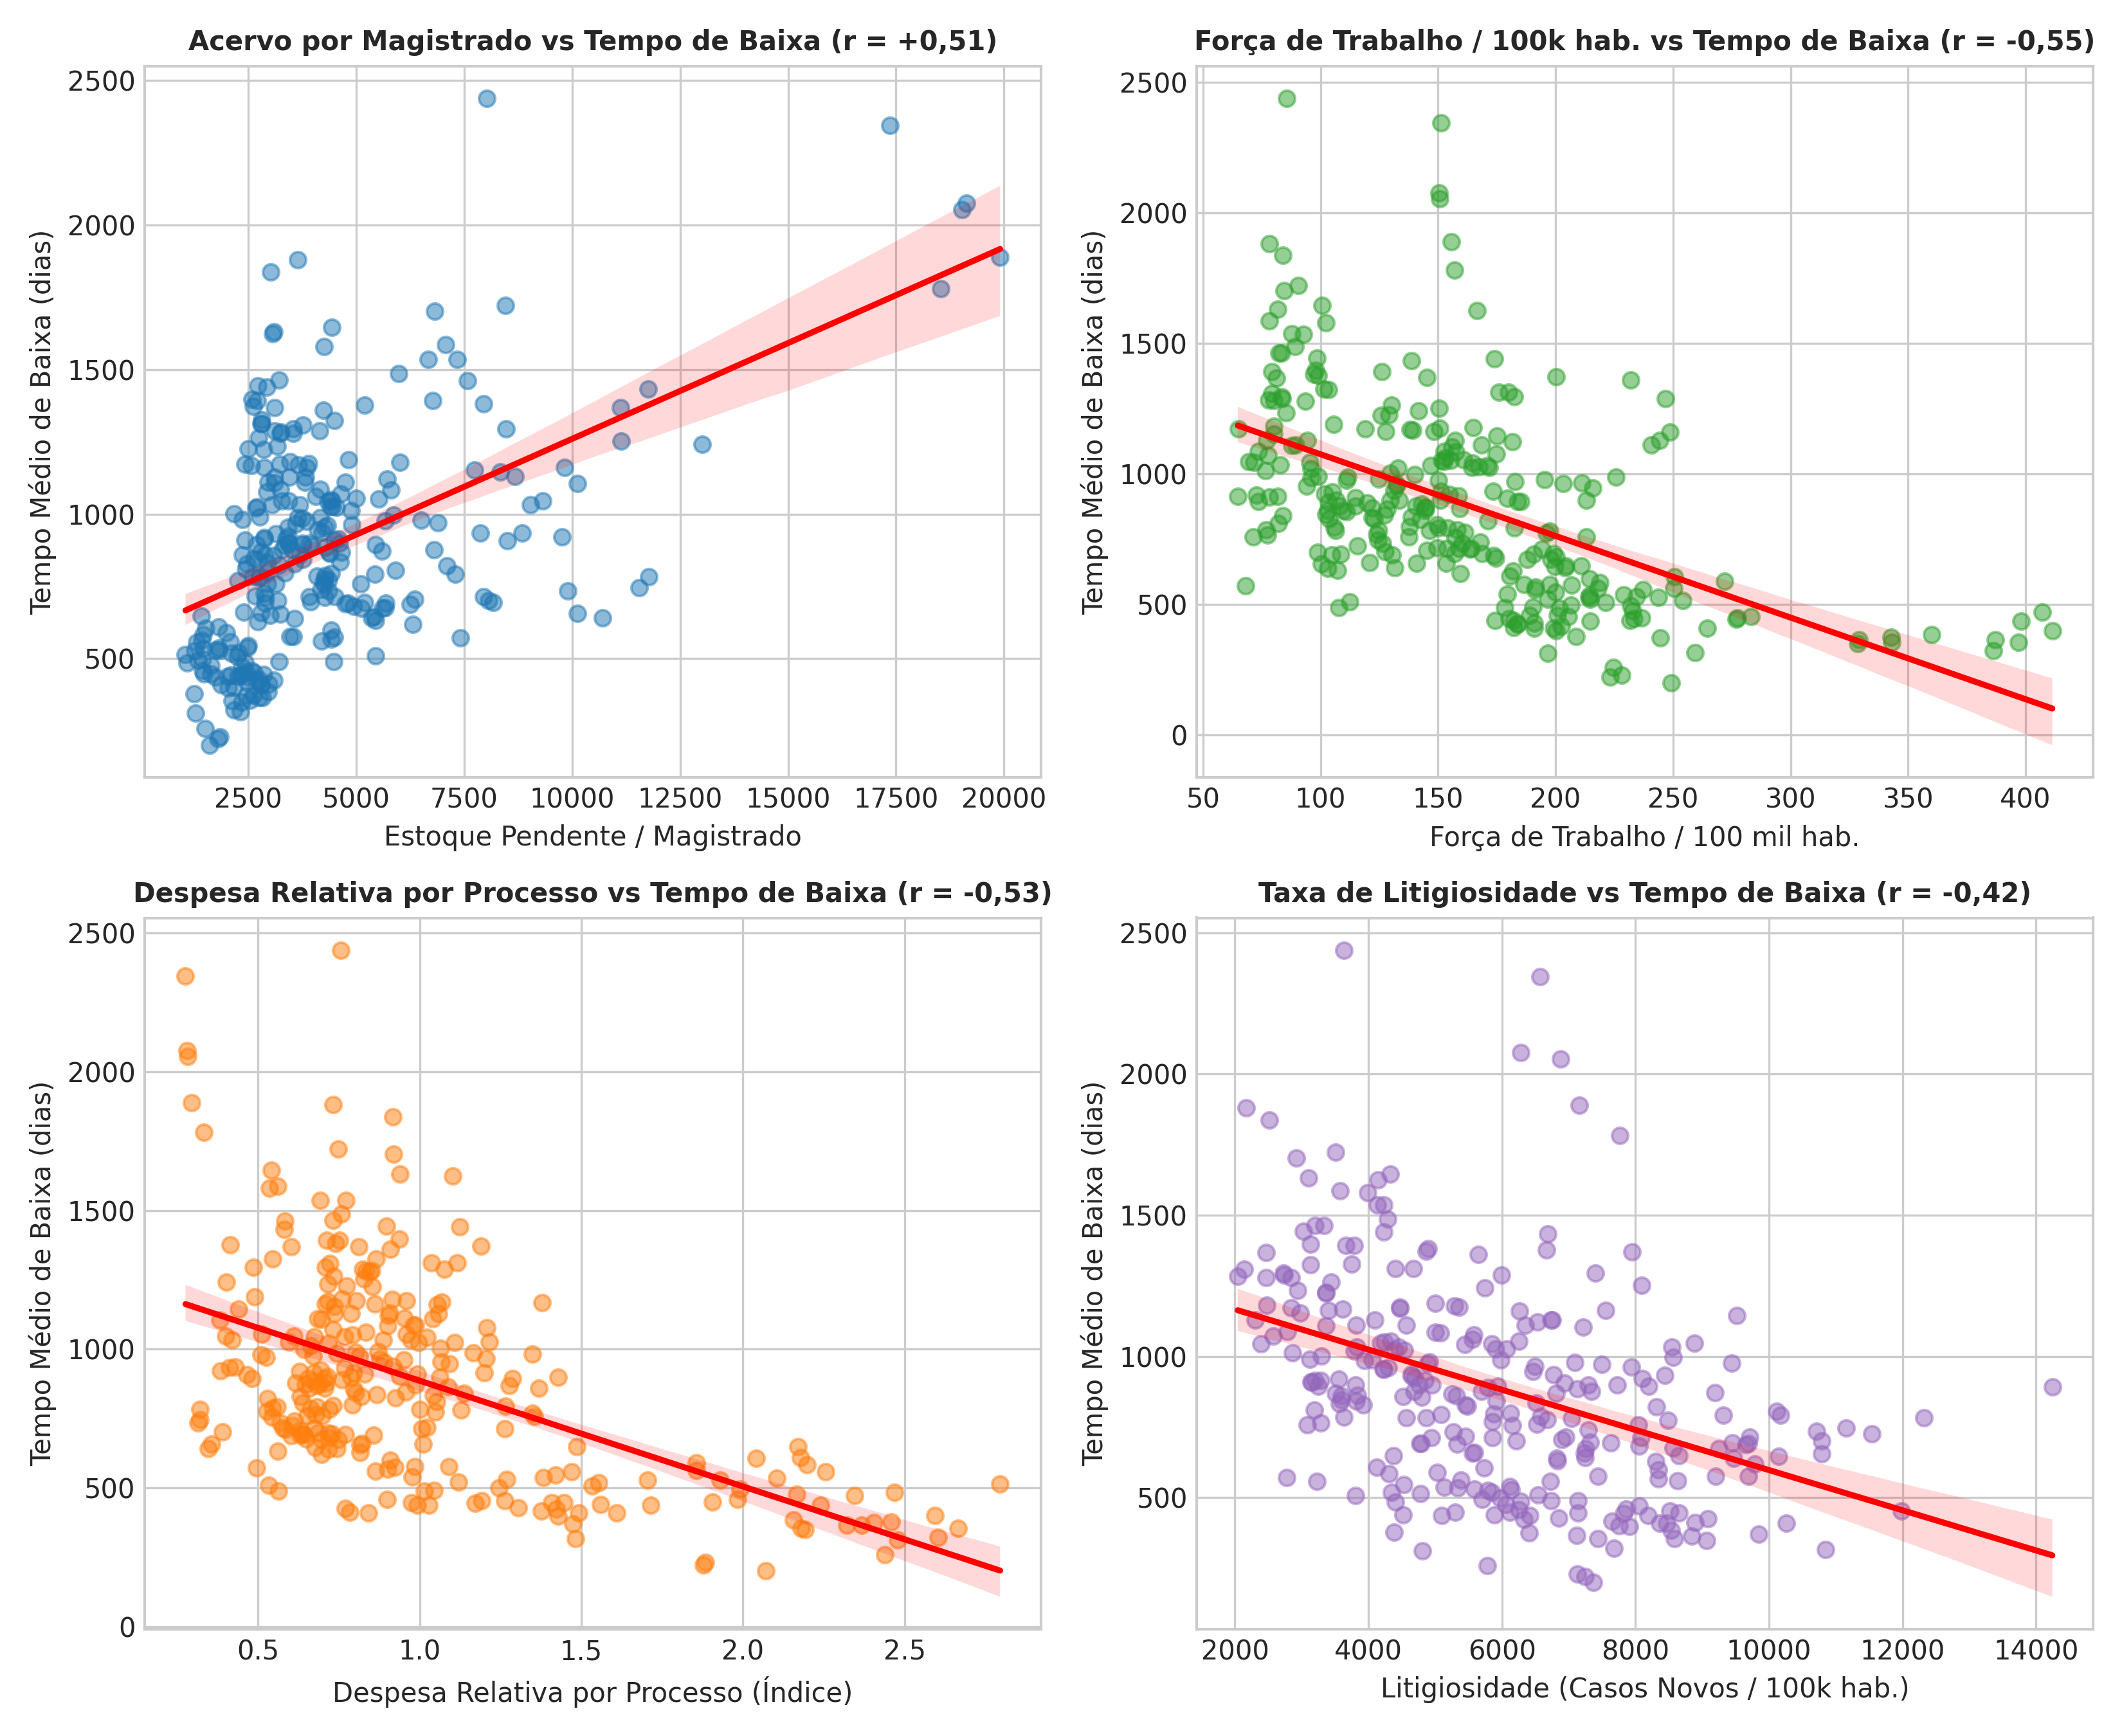

In [8]:
# Gráficos de dispersão com linha de tendência OLS
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
sns.regplot(data=df, x='estoque_por_magistrado', y='tpbaixcncrim1m', ax=axes[0, 0])
sns.regplot(data=df, x='f3', y='tpbaixcncrim1m', ax=axes[0, 1])
sns.regplot(data=df, x='despesa_rel', y='tpbaixcncrim1m', ax=axes[1, 0])
sns.regplot(data=df, x='litigiosidade', y='tpbaixcncrim1m', ax=axes[1, 1])
plt.tight_layout()
plt.show()

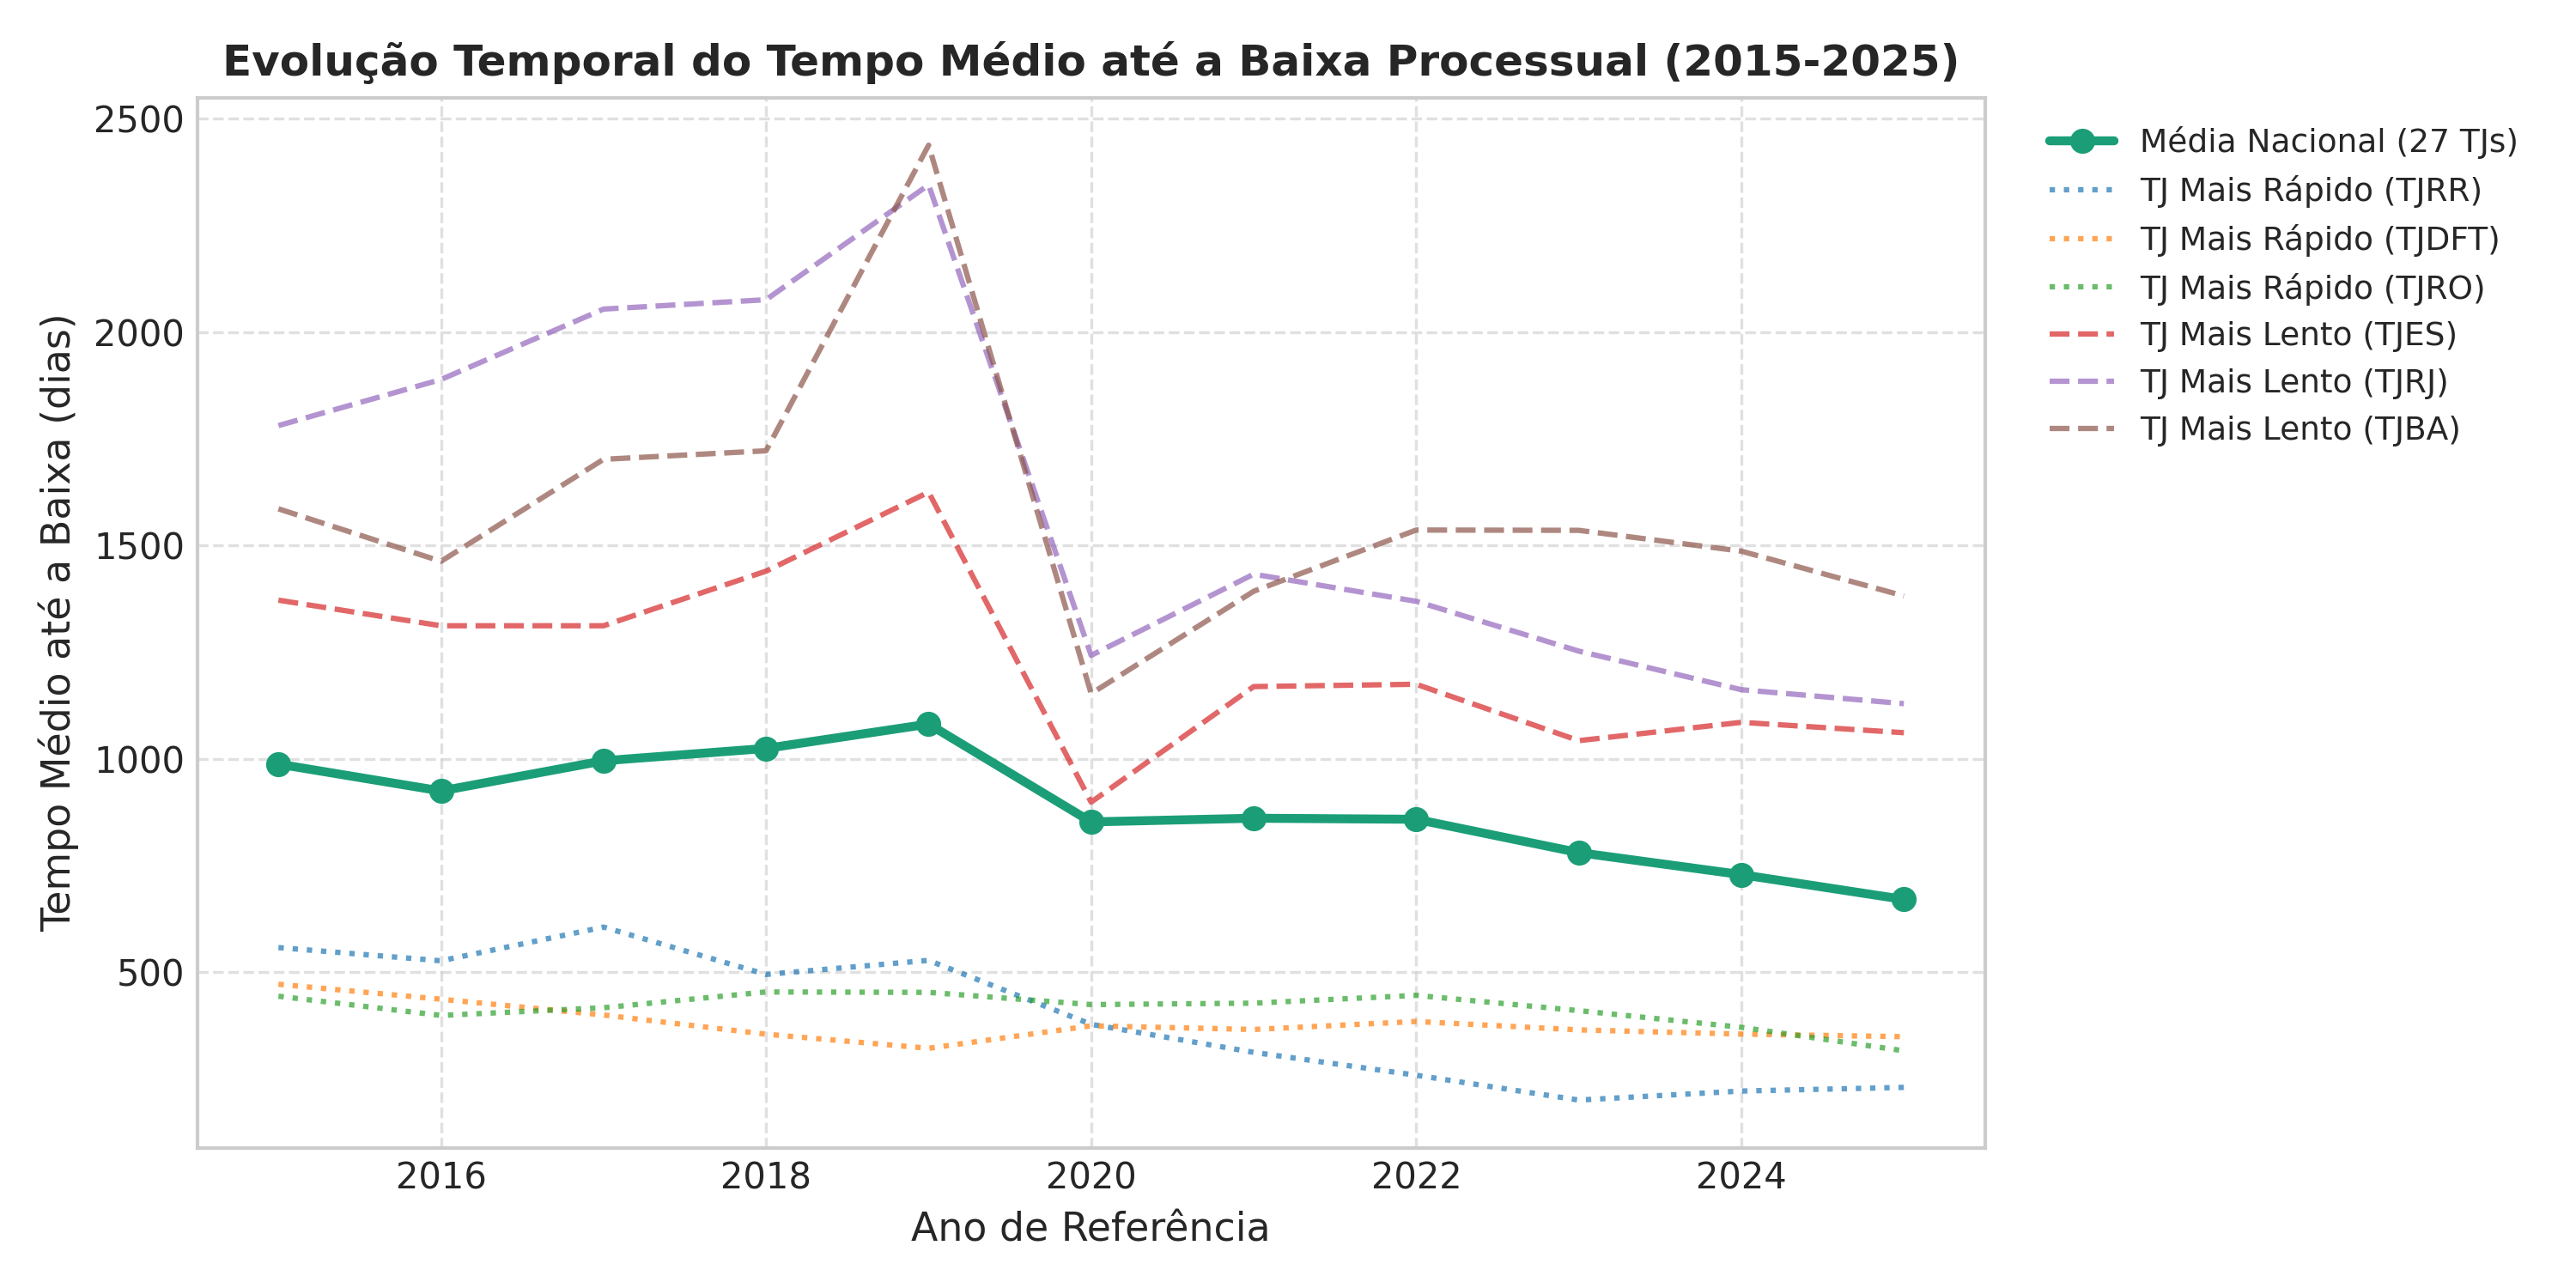

In [9]:
# Evolução Temporal da Média Nacional (2015-2025)
plt.figure(figsize=(10, 5))
evol = df.groupby('ano')['tpbaixcncrim1m'].mean()
plt.plot(evol.index, evol.values, marker='o', color='#1b9e77', linewidth=2.5)
plt.title('Evolução do Tempo Médio de Baixa (Média Nacional)')
plt.show()

## 5. Reflexões Críticas sobre Accountability, Governança e Tomada de Decisão

### 5.1 Governance e Accountability no Poder Judiciário
- **Accountability Vertical:** Transparência perante a sociedade civil sobre a produtividade e o tempo de resposta judicial.
- **Accountability Horizontal e Transversal:** Atuação do CNJ na padronização de metas (e.g., Meta 1 e Meta 2 do CNJ) e controle de gestão.

### 5.2 O Risco da Lei de Goodhart na Gestão Pública
Quando um indicador estatístico se torna meta de política pública, ele tende a perder seu poder de mensuração (*Goodhart's Law*). O foco exclusivo na "baixa estatística" pode gerar incentivos perversos, como baixas indevidas ou priorização de processos simples em detrimento de demandas complexas.

### 5.3 Diretrizes para Tomada de Decisão do Gestor Público
1. **Saneamento e Gestão de Acervos:** Políticas focadas na redução do `estoque_por_magistrado` através de mutirões de conciliação e triagem automatizada.
2. **Aporte Estratégico de Recursos:** Priorizar investimentos orçamentários em modernização tecnológica e inteligência artificial aplicadas ao fluxo processual.

## 6. Referências Bibliográficas

- BRASIL. **Constituição da República Federativa do Brasil de 1988**. Brasília, DF: Senado Federal, 1988.
- BRUCE, Andrew; BRUCE, Peter. **Estatística Prática para Cientistas de Dados: 50 Conceitos Fundamentais**. Rio de Janeiro: Alta Books, 2019.
- CONSELHO NACIONAL DE JUSTIÇA (CNJ). **Relatório Justiça em Números 2024 (ano-base 2023)**. Brasília: CNJ, 2024.
- WHEELAN, Charles. **Estatística: O que é, para que serve, como funciona**. São Paulo: Zahar, 2016.
